# TP 2 — Modèles génératifs avec PyTorch

| Informations académiques | Détails |
|---|---|
| **Nom et prénom** | Hachoum Mouad |
| **Filière** | INTELLIGENCE ARTIFICIELLE & SCIENCES DES DONNÉES |
| **Établissement** | EMSI Maarif |
| **Année universitaire** | 2026-2027 |
| **Module** | IA Générative Multimodale |
| **Enseignant** | Pr. Mohamed Youssfi |

**Objectifs :** charger MNIST, apprendre à classer, reconstruire et générer des chiffres,
comparer un classifieur, un autoencodeur (AE) et un autoencodeur variationnel (VAE).
Cette première partie ne lance aucun entraînement de GAN ni de diffusion.

**Provenance :** architectures, fonction de perte VAE et génération AE adaptées du support
`Modeles_generatifs_pytorch_avec_explications.ipynb` de **Pr. Mohamed Youssfi**.
Le [dépôt d’Amine Zmarrou](https://github.com/AmineZmarrou/Activit-Pratique-N-2-Mod-les-g-n-ratifs)
a été consulté comme référence avec son accord déclaré par l’étudiant. Les cellules utiles
y sont identiques au support officiel : elles sont reprises directement de ce dernier.
Aucun résultat, poids ou graphique d’Amine n’est utilisé. Voir [SOURCES.md](SOURCES.md).
Le support original reste local. Les explications, évaluations supplémentaires et contrôles
de reproduction ont été préparés avec l’assistance de Codex.

## 0. Environnement et reproductibilité

Installer les dépendances avec `uv sync --locked` dans `TP2`, sélectionner son Python 3.11,
puis exécuter toutes les cellules dans l’ordre depuis un noyau neuf, avec `TP2` comme
répertoire courant. CUDA est choisi si disponible. Les graines sont fixées à 42 ;
un autre matériel ou une autre version peut néanmoins modifier les résultats.

In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import json
import random
import platform
import time
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from torcheval.metrics import MulticlassAccuracy

SEED = 42
def fixer_graines(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

fixer_graines()
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
debut = time.perf_counter()
date_execution = datetime.now(timezone.utc).isoformat()
FIGURES = Path('figures')
POIDS = Path('poids')
FIGURES.mkdir(exist_ok=True)
POIDS.mkdir(exist_ok=True)
print('Python :', platform.python_version())
print('PyTorch :', torch.__version__, '| torchvision :', torchvision.__version__)
print('Périphérique :', torch.cuda.get_device_name() if device.type == 'cuda' else 'CPU')
print('CUDA PyTorch :', torch.version.cuda)

def afficher_figure(nom):
    plt.gcf().savefig(FIGURES / (nom + '.png'), dpi=130, bbox_inches='tight')
    plt.show()
    plt.close('all')

Python : 3.11.9
PyTorch : 2.9.1+cu128 | torchvision : 0.24.1+cu128
Périphérique : NVIDIA GeForce RTX 3060 Laptop GPU
CUDA PyTorch : 12.8


## 1. MNIST — données et exemples

MNIST comprend 60 000 images d’entraînement et 10 000 images de test, de taille 1 × 28 × 28.
`ToTensor()` transforme les pixels entiers en valeurs dans [0, 1], compatibles avec Sigmoid
et BCE. Les lots contiennent 128 images, sauf le dernier. Le jeu de test n’intervient
jamais dans l’optimisation. Un dossier MNIST local existant est réutilisé avant tout téléchargement.

Train : 60000 | Test : 10000 | lot : 128


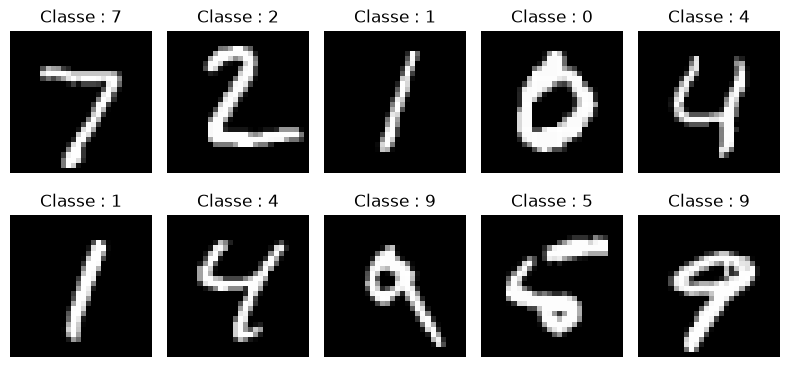

In [2]:
candidats = [Path('data'), Path('../data'), Path('../../data'), Path('../TP1-Bases-PyTorch/data')]
fichiers = ['train-images-idx3-ubyte', 'train-labels-idx1-ubyte',
            't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte']
data_root = next((p for p in candidats if all((p / 'MNIST' / 'raw' / f).is_file() for f in fichiers)), Path('data'))
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(data_root, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(data_root, train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED), pin_memory=device.type == 'cuda')
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=0,
                         pin_memory=device.type == 'cuda')
assert len(train_dataset) == 60000 and len(test_dataset) == 10000
print('Train :', len(train_dataset), '| Test :', len(test_dataset), '| lot :', train_loader.batch_size)
images, labels = next(iter(test_loader))
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Classe : {labels[i].item()}')
    ax.axis('off')
plt.tight_layout()
afficher_figure('01_exemples_mnist')

## 2. Modèle discriminatif — classification

Le classifieur estime P(y|x). `Flatten` transforme chaque image en 784 pixels ; les couches
784 → 128 → 10 produisent dix logits. ReLU apporte la non-linéarité.
`CrossEntropyLoss` applique elle-même le log-softmax : aucun Sigmoid ni Softmax n’est ajouté.
Adam utilise un taux d’apprentissage de 0,001 pendant **3 époques**.

In [3]:
# Source : Pr. Mohamed Youssfi, notebook officiel, cellule 8 (indice 0).
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)
historique_classifier = []
classifier.train()
for epoch in range(3):
    total_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = criterion(classifier(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    historique_classifier.append(total_loss / len(train_dataset))
    print(f'Époque {epoch+1}/3 — CE/image : {historique_classifier[-1]:.6f}')

classifier.eval()
metric = MulticlassAccuracy(device=device)
correct, total_ce = 0, 0.0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = classifier(x)
        metric.update(logits, y)
        correct += (logits.argmax(1) == y).sum().item()
        total_ce += F.cross_entropy(logits, y, reduction='sum').item()
accuracy = metric.compute().item()
assert abs(accuracy - correct / len(test_dataset)) < 1e-6
print(f'Accuracy test (torcheval) : {accuracy:.4%} ; calcul direct : {correct}/10000')
print(f'Entropie croisée test/image : {total_ce / len(test_dataset):.6f}')

Époque 1/3 — CE/image : 0.413045


Époque 2/3 — CE/image : 0.187887


Époque 3/3 — CE/image : 0.134698


Accuracy test (torcheval) : 96.4900% ; calcul direct : 9649/10000
Entropie croisée test/image : 0.122963


## 3. Autoencodeur simple — reconstruction

L’encodeur compresse 784 → 128 → 32 → **2**, puis le décodeur symétrique reconstruit
2 → 32 → 128 → 784 avec Sigmoid. La MSE moyenne sur les pixels mesure l’écart entre
entrée et reconstruction. Adam (`lr=0.001`) est utilisé pendant **5 époques**.
Les étiquettes ne participent pas à cet entraînement.

In [5]:
# Source : Pr. Mohamed Youssfi, notebook officiel, cellule 19 (indice 0).
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Époque 1/5 — MSE/pixel : 0.065266


Époque 2/5 — MSE/pixel : 0.052376


Époque 3/5 — MSE/pixel : 0.049012


Époque 4/5 — MSE/pixel : 0.046224


Époque 5/5 — MSE/pixel : 0.044566


MSE test/pixel : 0.044107


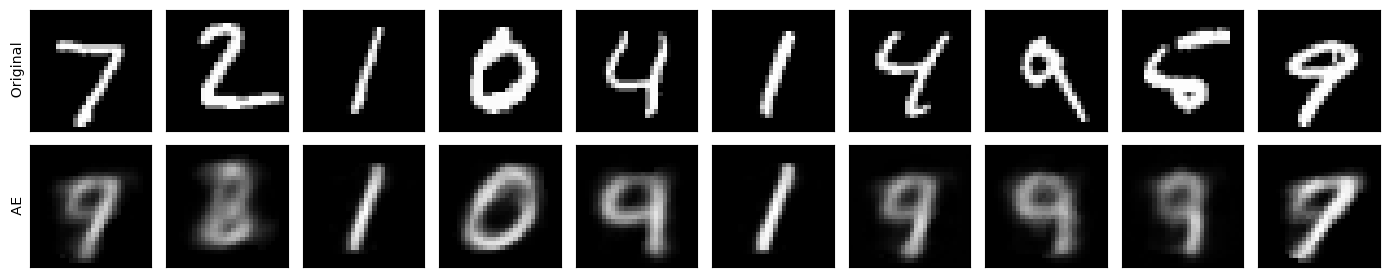

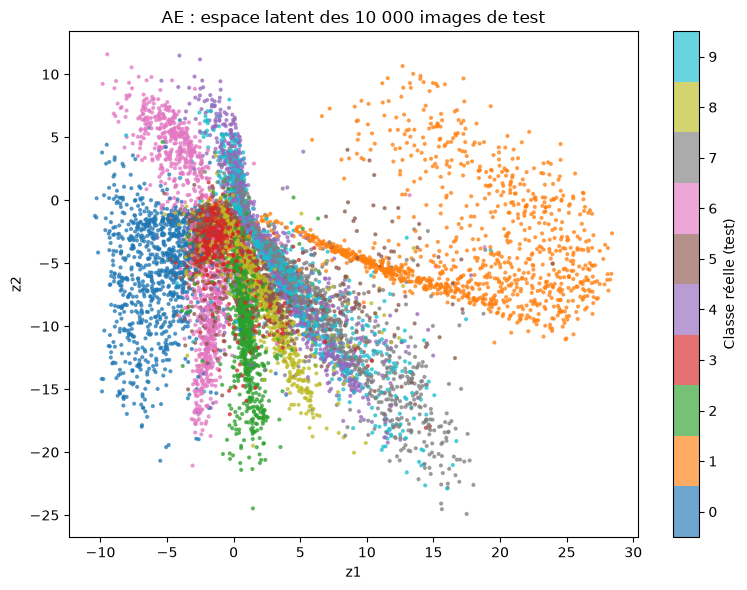

In [6]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=0.001)
historique_ae = []
ae.train()
for epoch in range(5):
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        loss = ae_criterion(ae(x), x)
        ae_optimizer.zero_grad()
        loss.backward()
        ae_optimizer.step()
        total_loss += loss.item() * x.size(0)
    historique_ae.append(total_loss / len(train_dataset))
    print(f'Époque {epoch+1}/5 — MSE/pixel : {historique_ae[-1]:.6f}')

ae.eval()
ae_sse = 0.0
zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        ae_sse += F.mse_loss(ae(x), x, reduction='sum').item()
        zs.append(ae.encode(x).cpu())
        ys.append(y)
ae_mse_test = ae_sse / (len(test_dataset) * 784)
Z, Y = torch.cat(zs).numpy(), torch.cat(ys).numpy()
print(f'MSE test/pixel : {ae_mse_test:.6f}')

@torch.no_grad()
def reconstructions(model, nom, variationnel=False):
    model.eval()
    x, _ = next(iter(test_loader))
    x = x[:10].to(device)
    sortie = model(x)
    reconstruit = sortie[0] if variationnel else sortie
    fig, axes = plt.subplots(2, 10, figsize=(14, 3))
    for i in range(10):
        for row, lot in enumerate([x.cpu(), reconstruit.cpu()]):
            axes[row, i].imshow(lot[i, 0], cmap='gray', vmin=0, vmax=1)
            axes[row, i].set_xticks([])
            axes[row, i].set_yticks([])
    axes[0, 0].set_ylabel('Original')
    axes[1, 0].set_ylabel(nom)
    plt.tight_layout()
    afficher_figure('reconstructions_' + nom.lower())

reconstructions(ae, 'AE')

def espace_latent(z, labels, titre, nom):
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(z[:, 0], z[:, 1], c=labels, s=4, cmap='tab10', vmin=-0.5, vmax=9.5, alpha=0.65)
    plt.colorbar(scatter, ticks=range(10), label='Classe réelle (test)')
    plt.xlabel('z1' if nom == 'ae' else 'mu1')
    plt.ylabel('z2' if nom == 'ae' else 'mu2')
    plt.title(titre)
    plt.tight_layout()
    afficher_figure('latent_' + nom)

espace_latent(Z, Y, 'AE : espace latent des 10 000 images de test', 'ae')

### Décoder la représentation moyenne d’une classe connue

On encode les images de classe **1 du jeu d’entraînement**, puis on décode leur code latent
moyen. Ce prototype utilise une classe connue ; il ne constitue pas un échantillonnage d’une
distribution générative apprise. Le centroïde peut même tomber entre plusieurs régions utiles.

In [7]:
# Source : Pr. Mohamed Youssfi, notebook officiel, cellule 32 (indice 0).
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

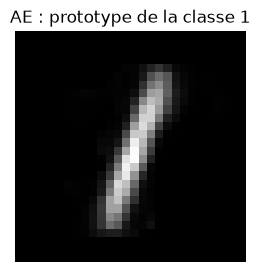

In [8]:
prototype = generer_chiffre(ae, train_loader, chiffre=1)
plt.figure(figsize=(3, 3))
plt.imshow(prototype[0, 0], cmap='gray', vmin=0, vmax=1)
plt.title('AE : prototype de la classe 1')
plt.axis('off')
afficher_figure('prototype_ae_classe_1')

L’AE n’impose aucune distribution à ses codes latents. Les classes peuvent se chevaucher,
les régions entre les codes peuvent être peu couvertes et une normale standard ne fournit
pas nécessairement des chiffres plausibles. La compression à deux dimensions et la MSE
favorisent aussi des reconstructions lissées et peuvent effacer des détails.

## 4. VAE — espace latent probabiliste et génération

L’encodeur 784 → 256 → 64 calcule deux vecteurs de dimension 2 : **mu** et **logvar**.
Le tirage `z = mu + exp(0.5 * logvar) * epsilon`, avec epsilon normal standard, rend
l’échantillonnage compatible avec la rétropropagation. Le décodeur suit 2 → 64 → 256 → 784
avec Sigmoid. L’objectif est **BCE sommée + beta × KL**, avec **beta=1**.
La KL rapproche la distribution conditionnelle de N(0,I). Adam (`lr=0.001`), **20 époques**.

In [9]:
# Source : Pr. Mohamed Youssfi, notebook officiel, cellule 38 (indice 0).
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [10]:
# Source : Pr. Mohamed Youssfi, notebook officiel, cellule 41 (indice 0).
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [11]:
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)
historique_vae = []
vae.train()
for epoch in range(20):
    totaux = np.zeros(3)
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, logvar = vae(x)
        loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=1.0)
        vae_optimizer.zero_grad()
        loss.backward()
        vae_optimizer.step()
        totaux += [loss.item(), rec.item(), kl.item()]
    valeurs = (totaux / len(train_dataset)).tolist()
    historique_vae.append(valeurs)
    print(f'Époque {epoch+1:02d}/20 — total/image={valeurs[0]:.4f}, BCE/image={valeurs[1]:.4f}, KL/image={valeurs[2]:.4f}')

Époque 01/20 — total/image=193.8184, BCE/image=189.6915, KL/image=4.1269


Époque 02/20 — total/image=165.8239, BCE/image=160.9486, KL/image=4.8753


Époque 03/20 — total/image=160.6317, BCE/image=155.4069, KL/image=5.2248


Époque 04/20 — total/image=156.7783, BCE/image=151.3101, KL/image=5.4681


Époque 05/20 — total/image=154.3200, BCE/image=148.6859, KL/image=5.6341


Époque 06/20 — total/image=152.4184, BCE/image=146.6697, KL/image=5.7487


... (10 outputs left out)

Époque 17/20 — total/image=143.5236, BCE/image=137.1280, KL/image=6.3956


Époque 18/20 — total/image=143.1263, BCE/image=136.7098, KL/image=6.4164


Époque 19/20 — total/image=142.8404, BCE/image=136.3978, KL/image=6.4426


Époque 20/20 — total/image=142.5683, BCE/image=136.1084, KL/image=6.4600


### Évaluation sur les 10 000 images de test

La perte VAE est évaluée avec un échantillon de z par image, comme à l’entraînement,
et une graine dédiée (43). On rapporte les sommes BCE et KL **par image**.
Une MSE supplémentaire utilise `decode(mu)` pour comparer des reconstructions déterministes
à celles de l’AE. Les objectifs MSE de l’AE et BCE+KL du VAE ont des unités différentes :
leurs valeurs brutes ne se comparent pas directement. Le test ne sert pas à choisir les hyperparamètres.

Test : total/image=144.036489, BCE/image=137.620930, KL/image=6.415558
MSE test/pixel de decode(mu) : 0.037783


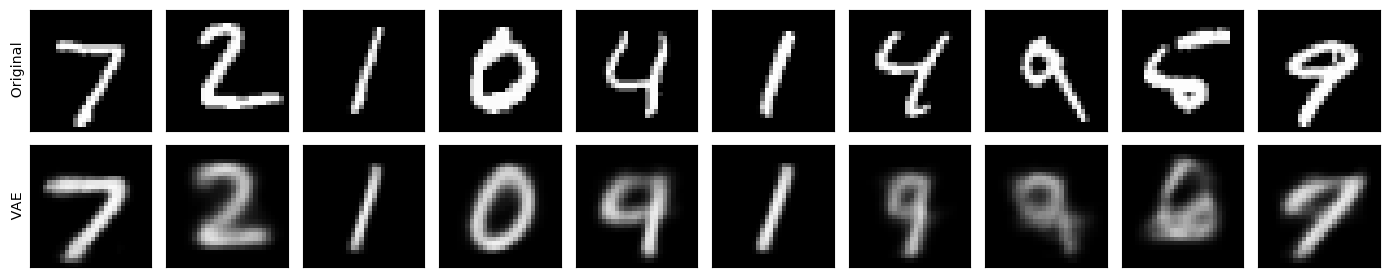

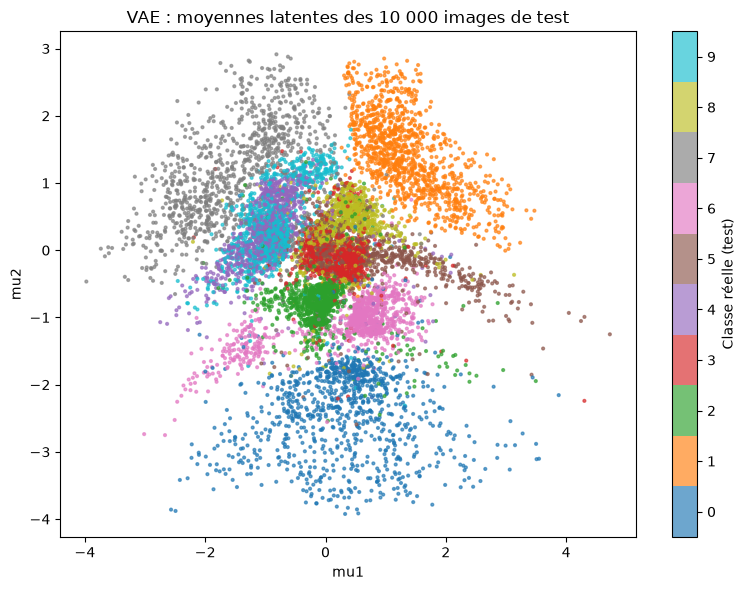

In [12]:
vae.eval()
totaux = np.zeros(3)
mus, vae_ys = [], []
vae_sse = 0.0
with torch.random.fork_rng(devices=[torch.cuda.current_device()] if device.type == 'cuda' else []):
    torch.manual_seed(SEED + 1)
    torch.cuda.manual_seed_all(SEED + 1)
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            x_hat, mu, logvar = vae(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=1.0)
            totaux += [loss.item(), rec.item(), kl.item()]
            vae_sse += F.mse_loss(vae.decode(mu), x, reduction='sum').item()
            mus.append(mu.cpu())
            vae_ys.append(y)
vae_test = (totaux / len(test_dataset)).tolist()
vae_mse_mu = vae_sse / (len(test_dataset) * 784)
MU = torch.cat(mus).numpy()
print(f'Test : total/image={vae_test[0]:.6f}, BCE/image={vae_test[1]:.6f}, KL/image={vae_test[2]:.6f}')
print(f'MSE test/pixel de decode(mu) : {vae_mse_mu:.6f}')
reconstructions(vae, 'VAE', variationnel=True)
espace_latent(MU, torch.cat(vae_ys).numpy(), 'VAE : moyennes latentes des 10 000 images de test', 'vae')

### Générer 20 nouvelles images

Les vecteurs proviennent de N(0,I), sans encoder d’image ni choisir d’étiquette.
Le VAE est non conditionnel : aucun contrôle explicite de la classe n’est disponible.
La plausibilité visuelle ne prouve ni l’originalité par rapport à MNIST ni une qualité quantitative.

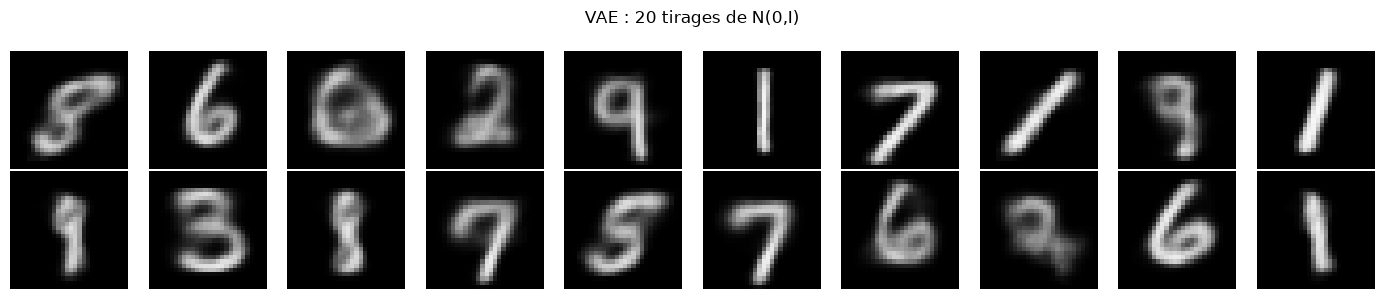

In [13]:
with torch.no_grad():
    z = torch.randn(20, 2, device=device)
    samples = vae.decode(z).cpu()
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image[0], cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle('VAE : 20 tirages de N(0,I)')
plt.tight_layout()
afficher_figure('vae_20_generations')

### Explorer une grille de 15 × 15 points entre −3 et 3

Chaque tuile est un décodage d’un couple (z1,z2). Les transitions permettent d’examiner la
continuité du décodeur ; les extrémités sont moins probables sous la normale standard.

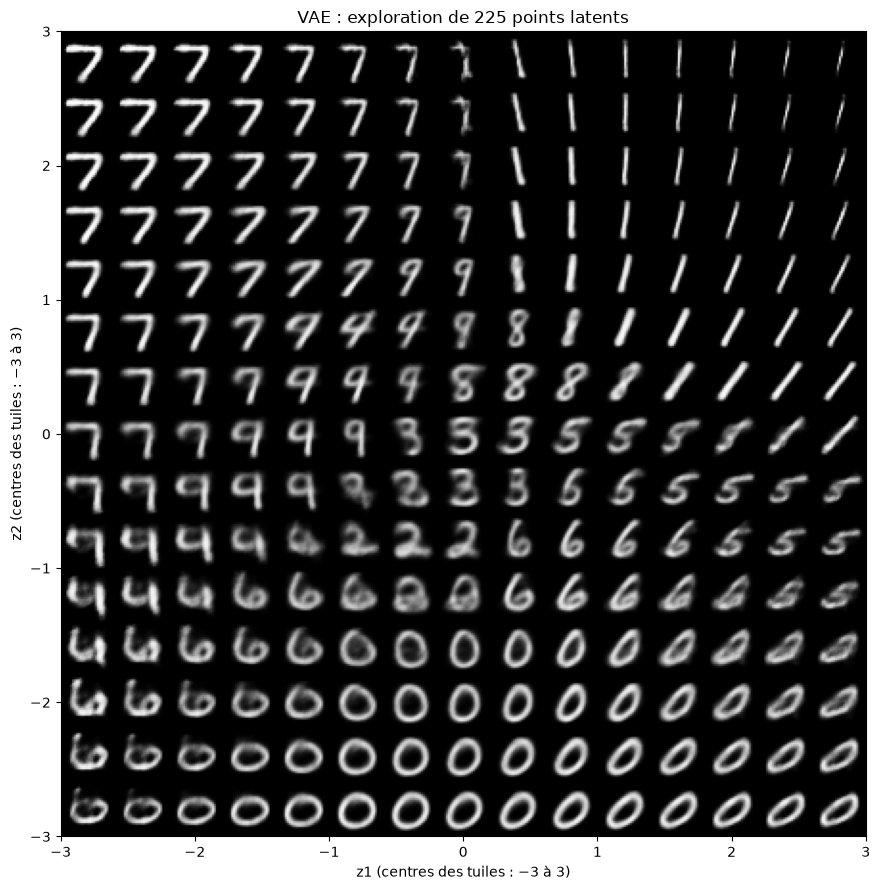

In [14]:
grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(3, -3, 15)
figure = np.zeros((28 * 15, 28 * 15))
with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            figure[i*28:(i+1)*28, j*28:(j+1)*28] = vae.decode(z).cpu().numpy()[0, 0]
plt.figure(figsize=(9, 9))
plt.imshow(figure, cmap='gray', vmin=0, vmax=1, extent=[-3, 3, -3, 3])
plt.xlabel('z1 (centres des tuiles : −3 à 3)')
plt.ylabel('z2 (centres des tuiles : −3 à 3)')
plt.title('VAE : exploration de 225 points latents')
plt.tight_layout()
afficher_figure('vae_grille_15x15')

## 5. Courbes d’apprentissage et sauvegarde

Les moyennes d’époque sont pondérées par le nombre d’images : le dernier lot incomplet
ne reçoit pas le même poids qu’un lot de 128. La perte VAE d’entraînement conserve
la réduction `sum` du professeur pour le gradient, puis est divisée par le nombre d’images
uniquement pour le compte rendu. Chaque modèle est rechargé et vérifié sur **tout le test**.

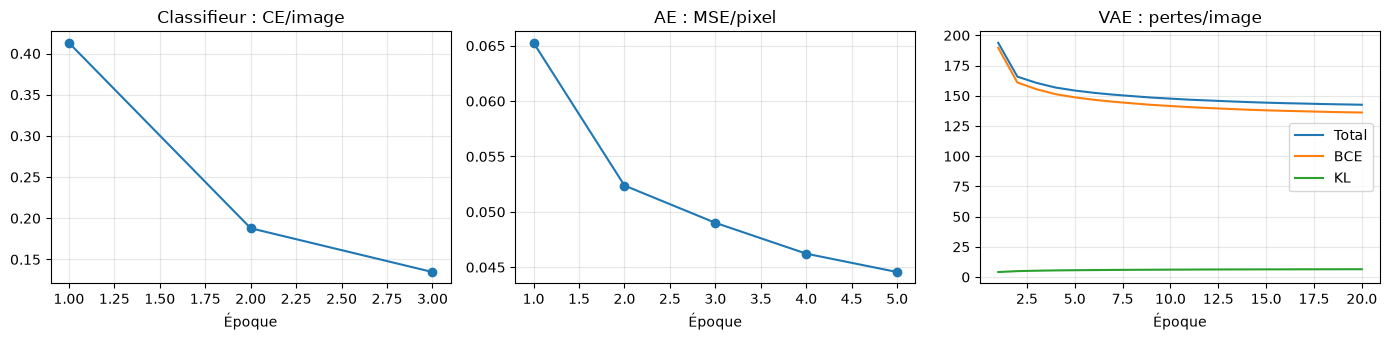

classifier : sauvegarde/rechargement identiques sur les 10 000 images de test


autoencoder : sauvegarde/rechargement identiques sur les 10 000 images de test


vae : sauvegarde/rechargement identiques sur les 10 000 images de test
Résultats sauvegardés : resultats_tp2.json


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(range(1, 4), historique_classifier, marker='o')
axes[0].set_title('Classifieur : CE/image')
axes[1].plot(range(1, 6), historique_ae, marker='o')
axes[1].set_title('AE : MSE/pixel')
h = np.array(historique_vae)
for i, nom in enumerate(['Total', 'BCE', 'KL']):
    axes[2].plot(range(1, 21), h[:, i], label=nom)
axes[2].set_title('VAE : pertes/image')
axes[2].legend()
for ax in axes:
    ax.set_xlabel('Époque')
    ax.grid(alpha=0.3)
plt.tight_layout()
afficher_figure('courbes_apprentissage')

rechargement = {}
for nom, model, constructeur in [('classifier', classifier, Classifier), ('autoencoder', ae, Autoencoder), ('vae', vae, VAE)]:
    fichier = POIDS / (nom + '_mnist.pth')
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, fichier)
    # fork_rng préserve les tirages des expériences suivantes.
    with torch.random.fork_rng(devices=[torch.cuda.current_device()] if device.type == 'cuda' else []):
        copie = constructeur().to(device)
    copie.load_state_dict(torch.load(fichier, map_location=device, weights_only=True))
    copie.eval()
    model.eval()
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            if nom == 'vae':
                mu1, logvar1 = model.encode(x)
                mu2, logvar2 = copie.encode(x)
                assert torch.equal(mu1, mu2) and torch.equal(logvar1, logvar2)
                assert torch.equal(model.decode(mu1), copie.decode(mu2))
            else:
                assert torch.equal(model(x), copie(x))
    rechargement[nom] = {'identique': True, 'images_test': len(test_dataset)}
    print(nom, ': sauvegarde/rechargement identiques sur les 10 000 images de test')

resultats = {
    'date_utc': date_execution, 'seed': SEED,
    'environnement': {'python': platform.python_version(), 'torch': torch.__version__,
        'torchvision': torchvision.__version__, 'cuda_runtime': torch.version.cuda,
        'device': device.type, 'gpu': torch.cuda.get_device_name() if device.type == 'cuda' else None},
    'protocole': {'train': len(train_dataset), 'test': len(test_dataset), 'batch_size': 128,
        'transform': 'ToTensor', 'lr': 0.001, 'epochs_classifier': 3, 'epochs_ae': 5,
        'epochs_vae': 20, 'latent_dim': 2, 'beta': 1.0},
    'classifier': {'accuracy_test': accuracy, 'correct_test': correct,
        'ce_test_par_image': total_ce / len(test_dataset), 'historique_ce': historique_classifier},
    'autoencoder': {'mse_test_par_pixel': ae_mse_test, 'historique_mse': historique_ae},
    'vae': {'total_test_par_image': vae_test[0], 'bce_test_par_image': vae_test[1],
        'kl_test_par_image': vae_test[2], 'mse_mu_test_par_pixel': vae_mse_mu,
        'evaluation_mc_echantillons_par_image': 1, 'evaluation_seed': SEED+1,
        'historique_total_bce_kl': historique_vae},
    'rechargement': rechargement,
    'duree_secondes': time.perf_counter() - debut,
}
Path('resultats_tp2.json').write_text(json.dumps(resultats, indent=2, ensure_ascii=False), encoding='utf-8')
print('Résultats sauvegardés : resultats_tp2.json')

## 6. Conclusion — classification, reconstruction et génération

| Modèle | Apprentissage | Utilisation | Limite principale |
|---|---|---|---|
| Discriminatif | Image → classe ; étiquettes requises | Classifier un chiffre | Ne génère pas d’image |
| AE | Image → code → image ; MSE | Reconstruire, explorer un code compact | Pas de distribution latente imposée |
| VAE | Distribution latente → image ; BCE + KL | Reconstruire et échantillonner N(0,I) | Compromis reconstruction/régularisation, images lissées |

L’AE reconstruit une image donnée ; décoder un centroïde de classe fournit un prototype.
Le VAE apprend aussi une organisation probabiliste qui rend possible la génération sans
image d’entrée. Les nuages latents sont colorés après entraînement avec les classes du test :
cette visualisation ne signifie pas que les modèles génératifs ont utilisé ces étiquettes.

### Lecture des figures obtenues

Les courbes diminuent sur les trois entraînements. Pour le VAE, le total passe de
193,8184 à 142,5683 par image, tandis que la KL augmente de 4,1269 à 6,4600 :
l’amélioration de reconstruction s’accompagne d’un coût accru d’écart au prior.
La perte test totale de 144,0365 est proche de la dernière moyenne d’entraînement,
sans permettre à elle seule de conclure à une généralisation parfaite.

Sur les dix exemples présentés, l’AE préserve bien les traits verticaux des 1 et la
boucle du 0, mais certains 7 et 4 ressemblent à des 9 après reconstruction. Les
nuages latents présentent des chevauchements, notamment entre plusieurs chiffres
à boucles. Les codes des 1 forment une région assez distincte et leur code moyen
donne un prototype vertical reconnaissable.

Le VAE reconstruit visuellement mieux certains 7 et 2 de cet échantillon, tout en
conservant des confusions et du flou sur plusieurs chiffres. Ses vingt tirages
comprennent des formes reconnaissables de 1, 2, 3, 6 et 7, ainsi que des formes
ambiguës. La grille montre des transitions graduelles entre régions de 7, de 1 et
de chiffres à boucles ; une même forme se répète dans plusieurs tuiles voisines.
Cela illustre un espace décodable continu, sans garantir la séparation des dix
classes ni une diversité uniforme. Ces observations portent sur les figures de
cette exécution et complètent les métriques, sans les remplacer.


In [16]:
comparaison = 'plus faible' if vae_mse_mu < ae_mse_test else 'plus élevée'
display(Markdown(f"""
### Résultats de cette exécution

- **Classifieur : {accuracy:.2%} d’accuracy**, soit {correct}/10 000 prédictions correctes après 3 époques.
- **AE : MSE test/pixel = {ae_mse_test:.6f}** après 5 époques.
- **VAE : BCE/image = {vae_test[1]:.4f}, KL/image = {vae_test[2]:.4f}, total/image = {vae_test[0]:.4f}** après 20 époques.
- Le décodage de mu du VAE donne une **MSE/pixel = {vae_mse_mu:.6f}**, {comparaison} que celle de l’AE.

Cette comparaison porte sur les protocoles imposés : les architectures, pertes et nombres
d’époques diffèrent. Elle ne permet pas d’attribuer l’écart à la seule régularisation KL.
La KL mesurée quantifie le coût de régularisation, sans prouver que le posterior agrégé
est exactement normal. Les 20 tirages et la grille montrent le comportement du décodeur ;
ils ne constituent pas une mesure statistique de qualité ou de diversité.
Les trois sauvegardes reproduisent exactement leurs sorties déterministes sur tout le test.
"""))


### Résultats de cette exécution

- **Classifieur : 96.49% d’accuracy**, soit 9649/10 000 prédictions correctes après 3 époques.
- **AE : MSE test/pixel = 0.044107** après 5 époques.
- **VAE : BCE/image = 137.6209, KL/image = 6.4156, total/image = 144.0365** après 20 époques.
- Le décodage de mu du VAE donne une **MSE/pixel = 0.037783**, plus faible que celle de l’AE.

Cette comparaison porte sur les protocoles imposés : les architectures, pertes et nombres
d’époques diffèrent. Elle ne permet pas d’attribuer l’écart à la seule régularisation KL.
La KL mesurée quantifie le coût de régularisation, sans prouver que le posterior agrégé
est exactement normal. Les 20 tirages et la grille montrent le comportement du décodeur ;
ils ne constituent pas une mesure statistique de qualité ou de diversité.
Les trois sauvegardes reproduisent exactement leurs sorties déterministes sur tout le test.


### Sources et contributions

- **Pr. Mohamed Youssfi**, `Modeles_generatifs_pytorch_avec_explications.ipynb`, cellules 2–55
  (indices 0), référence officielle conservée localement. Les classes `Classifier`,
  `Autoencoder`, `VAE`, `vae_loss` et `generer_chiffre` viennent directement de ce support.
  Les boucles et visualisations sont adaptées à la traçabilité des résultats.
- **Amine Zmarrou**, [dépôt de référence, révision consultée](https://github.com/AmineZmarrou/Activit-Pratique-N-2-Mod-les-g-n-ratifs/tree/715692e6188e7b21a820177dc0652185a3903218),
  branche `master`. Consultation et comparaison ; aucun élément spécifique à son travail,
  aucun résultat ni poids n’est republié. L’absence de licence et la validation des règles
  de collaboration sont détaillées dans [SOURCES.md](SOURCES.md).
- [PyTorch : versions et paires compatibles](https://pytorch.org/get-started/previous-versions/)
  et [UV : intégration PyTorch](https://docs.astral.sh/uv/guides/integration/pytorch/).
- Intégration, rédaction, calculs locaux et contrôles préparés pour **Hachoum Mouad**, avec
  l’assistance de **Codex**. Ce rendu ne revendique pas l’originalité des architectures pédagogiques.